In [1]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import trustworthiness

sns.set_theme(style="whitegrid"); plt.rcParams.update({'font.size': 10})
                   
DATA_PATH = '/kaggle/input/datasets/caceelizaalexandra/tabel-date/tabel_aliniat_CP1_Cace (1).csv'

df = pd.read_csv(DATA_PATH, parse_dates=['date'])

# Setul de date conține exclusiv ianuarie, februarie și iunie–august.
# Iarna: ianuarie–februarie.
# Vara: iunie–august.
df['sezon'] = df['date'].dt.month.map({
    1: 'iarna',
    2: 'iarna',
    6: 'vara',
    7: 'vara',
    8: 'vara'
})

GRUPURI = {'Sensor.Community': ['PM2.5', 'PM10'],
           'ERA5': ['temperatura', 'umiditate_punct_roua', 'viteza_vant', 'boundary_layer_height', 'presiune_suprafata'],
           'S5P': ['NO2_satelit']}
TOATE = [c for g in GRUPURI.values() for c in g]
METEO = GRUPURI['ERA5']

n_senz, n_zile = df['sensor_id'].nunique(), df['date'].nunique()
posibile = n_senz * n_zile
print(f"Matricea X: n = {len(df)} observații (senzor × zi), d = {len(TOATE)} trăsături")
print(f"{n_senz} senzori × {n_zile} zile = {posibile} posibile; prezente {len(df)} ({len(df)/posibile:.1%})")
print(f"Iarnă: {df.loc[df.sezon=='iarna','date'].nunique()} zile · Vară: {df.loc[df.sezon=='vara','date'].nunique()} zile")

Matricea X: n = 1397 observații (senzor × zi), d = 8 trăsături
10 senzori × 151 zile = 1510 posibile; prezente 1397 (92.5%)
Iarnă: 59 zile · Vară: 92 zile


In [2]:
PROV = {  # trăsătură: (unitate, derivare, transformare)
 'PM2.5': ('µg/m³', 'Sensor.Community: medie zilnică (UTC) a măsurătorilor valide', 'log1p → standardizare'),
 'PM10':  ('µg/m³', 'Sensor.Community: medie zilnică (UTC) a măsurătorilor valide', 'log1p → standardizare'),
 'temperatura': ('°C', 'ERA5 t2m: medie zilnică a valorilor orare, medie pe 2 puncte de grilă', 'standardizare'),
 'umiditate_punct_roua': ('°C', 'ERA5 d2m: medie zilnică a valorilor orare, 2 puncte de grilă', 'standardizare'),
 'viteza_vant': ('m/s', 'ERA5 u10, v10: modul orar, apoi medie zilnică', 'standardizare'),
 'boundary_layer_height': ('m', 'ERA5 blh: medie zilnică a valorilor orare', 'standardizare'),
 'presiune_suprafata': ('Pa', 'ERA5 sp: medie zilnică a valorilor orare', 'standardizare'),
 'NO2_satelit': ('µmol/m²', 'S5P TROPOMI (colecția OFFL), GEE: coloană troposferică, medie urbană; negative trunchiate la 0', '×10⁶ → log1p → standardizare'),
}
meta = pd.DataFrame([(c, s, *PROV[c]) for s, cs in GRUPURI.items() for c in cs],
                    columns=['trasatura', 'sursa', 'unitate', 'derivare', 'transformare'])
for nume, mask in [('lipsa_%', slice(None)), ('lipsa_iarna_%', df.sezon == 'iarna'), ('lipsa_vara_%', df.sezon == 'vara')]:
    sub = df if nume == 'lipsa_%' else df[mask]
    meta[nume] = [round(sub[c].isna().mean() * 100, 1) for c in meta.trasatura]
meta.to_csv( 'cp2_matrice_X_documentata.csv', index=False); display(meta)

,trasatura,sursa,unitate,derivare,transformare,lipsa_%,lipsa_iarna_%,lipsa_vara_%
0,PM2.5,Sensor.Community,µg/m³,Sensor.Community: medie zilnică (UTC) a măsură...,log1p → standardizare,0.0,0.0,0.0
1,PM10,Sensor.Community,µg/m³,Sensor.Community: medie zilnică (UTC) a măsură...,log1p → standardizare,0.0,0.0,0.0
2,temperatura,ERA5,°C,"ERA5 t2m: medie zilnică a valorilor orare, med...",standardizare,0.0,0.0,0.0
3,umiditate_punct_roua,ERA5,°C,"ERA5 d2m: medie zilnică a valorilor orare, 2 p...",standardizare,0.0,0.0,0.0
4,viteza_vant,ERA5,m/s,"ERA5 u10, v10: modul orar, apoi medie zilnică",standardizare,0.0,0.0,0.0
5,boundary_layer_height,ERA5,m,ERA5 blh: medie zilnică a valorilor orare,standardizare,0.0,0.0,0.0
6,presiune_suprafata,ERA5,Pa,ERA5 sp: medie zilnică a valorilor orare,standardizare,0.0,0.0,0.0
7,NO2_satelit,S5P,µmol/m²,"S5P TROPOMI (colecția OFFL), GEE: coloană trop...",×10⁶ → log1p → standardizare,29.3,64.7,4.5


Rânduri marcate ca anomalie: 6 din 1397


,date,sensor_id,PM2.5,PM10,mediana_zilei
484,2026-07-31,65256,212.0849,233.0216,5.2
485,2026-08-01,65256,282.7516,312.5519,6.2
486,2026-08-02,65256,341.6770,376.4526,6.7
487,2026-08-03,65256,339.6468,374.3528,7.1
488,2026-08-04,65256,335.9016,371.5687,9.5
489,2026-08-05,65256,272.4020,303.9409,7.6


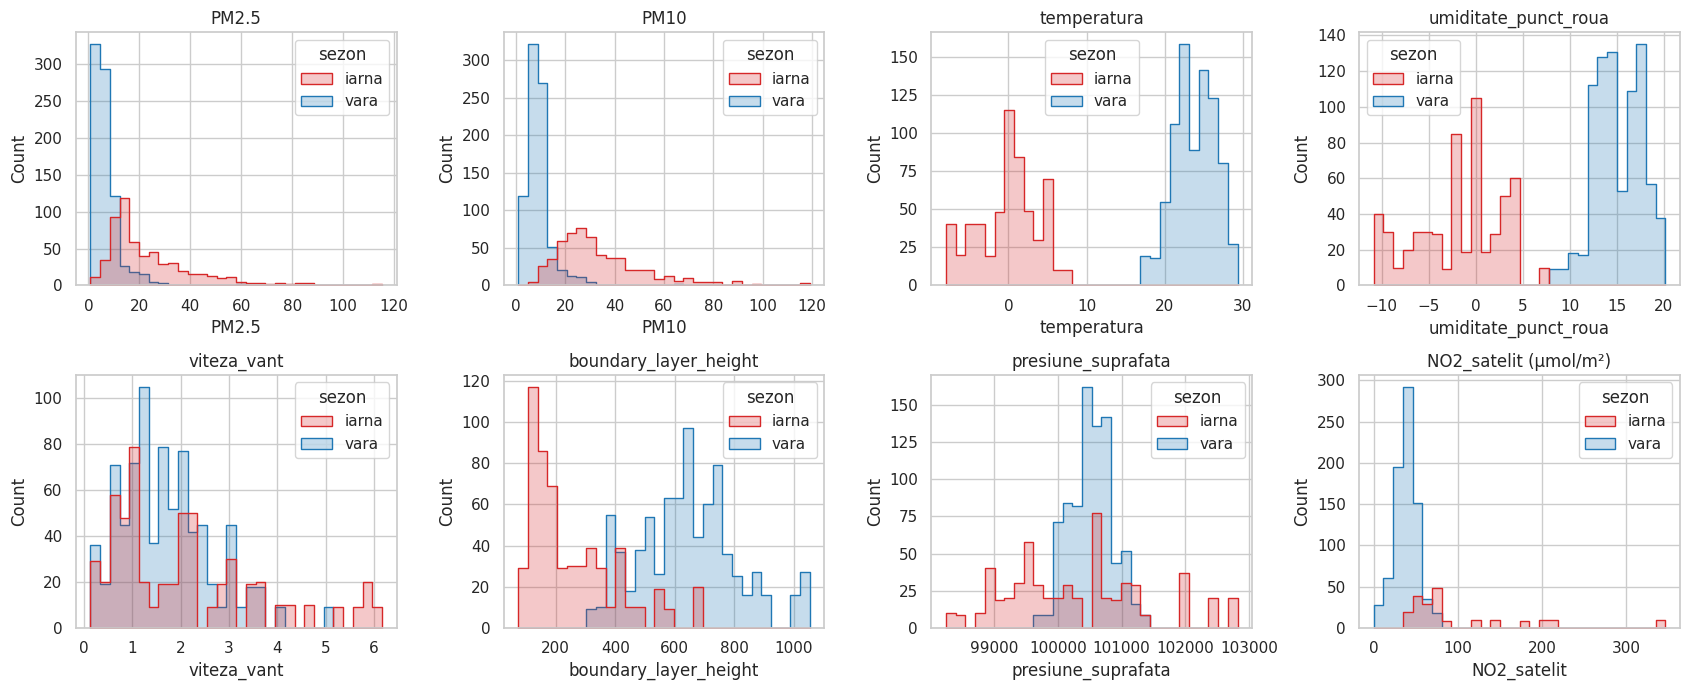

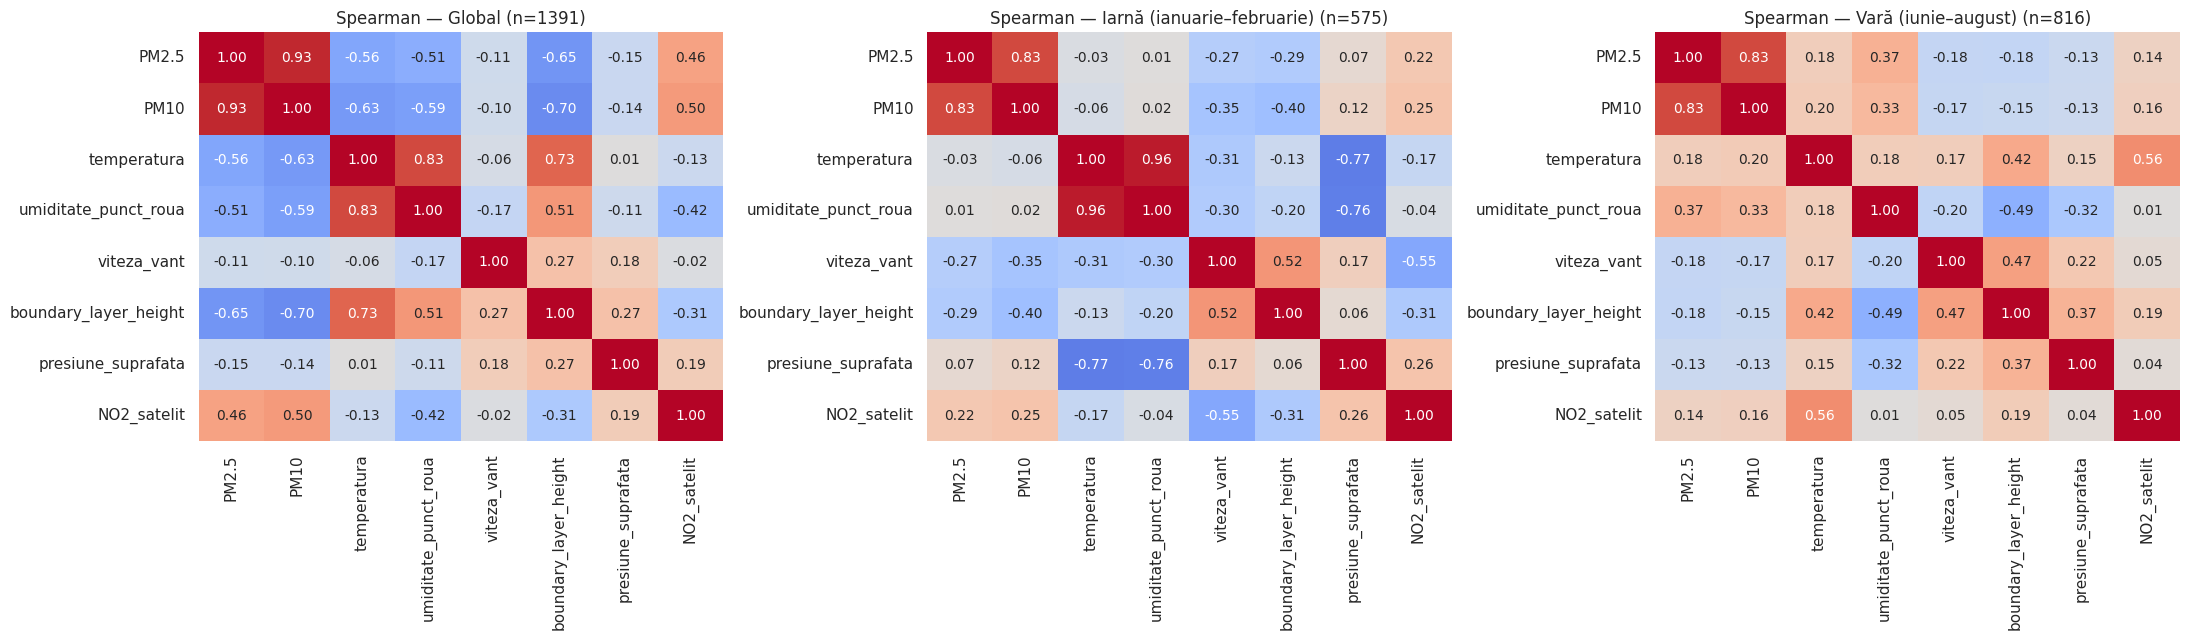

sezon                              iarna        vara
PM2.5                 mean        24.176       6.921
                      median      17.753       5.503
                      std         17.513       6.596
                      min          1.031       0.787
                      max        115.293      91.654
PM10                  mean        34.117       9.140
                      median      29.475       8.289
                      std         18.396       6.992
                      min          1.728       0.787
                      max        119.210     100.149
temperatura           mean        -0.055      23.750
                      median       0.361      23.959
                      std          3.846       2.682
                      min         -7.995      17.415
                      max          7.791      29.318
umiditate_punct_roua  mean        -1.845      15.108
                      median      -1.274      14.959
                      std          4.609       2.533
                      min        -10.874       8.083
                      max          6.944      20.201
viteza_vant           mean         2.086       1.689
                      median       1.766       1.572
                      std          1.557       0.939
                      min          0.164       0.129
                      max          6.165       4.964
boundary_layer_height mean       253.230     641.975
                      median     196.238     639.494
                      std        148.225     166.502
                      min         73.205     314.917
                      max        675.324    1055.046
presiune_suprafata    mean    100304.572  100519.222
                      median  100155.230  100521.125
                      std       1093.119     326.738
                      min      98245.570   99713.230
                      max     102820.870  101321.160
NO2_satelit           mean       102.763      38.632
                      median      71.210      38.564
                      std         74.845      13.784
                      min         40.321       0.000
                      max        346.769      73.704

In [3]:
med_zi = df.groupby('date')['PM2.5'].transform('median')

df['anomalie'] = (df['PM2.5'] / med_zi > 5) & (df['PM2.5'] > 100)
print(f"Rânduri marcate ca anomalie: {df.anomalie.sum()} din {len(df)}")
display(df.loc[df.anomalie, ['date', 'sensor_id', 'PM2.5', 'PM10']].assign(mediana_zilei=med_zi[df.anomalie].round(1)))

# Analiza univariată și bivariată
ok = ~df['anomalie']
brut = df[ok].copy(); brut['NO2_satelit'] *= 1e6                       # doar pentru afișare, µmol/m²
fig, ax = plt.subplots(2, 4, figsize=(17, 7))
for a, c in zip(ax.ravel(), TOATE):
    sns.histplot(data=brut, x=c, hue='sezon', bins=30, element='step', ax=a, palette={'iarna': '#d62728', 'vara': '#1f77b4'})
    a.set_title(c + (' (µmol/m²)' if c == 'NO2_satelit' else ''))
plt.tight_layout(); plt.savefig('cp2_distributii.png', dpi=200); plt.show()

fig, ax = plt.subplots(1, 3, figsize=(22, 6.5))

for a, (nume, sub) in zip(
    ax,
    [
        ('Global', brut),
        ('Iarnă (ianuarie–februarie)', brut[brut.sezon == 'iarna']),
        ('Vară (iunie–august)', brut[brut.sezon == 'vara'])
    ]
):
    sns.heatmap(
        sub[TOATE].corr(method='spearman'),
        annot=True,
        fmt='.2f',
        cmap='coolwarm',
        vmin=-1,
        vmax=1,
        ax=a,
        cbar=False
    )
    a.set_title(f'Spearman — {nume} (n={len(sub)})')

plt.tight_layout()
plt.savefig('cp2_corelatii_global_si_pe_sezon.png', dpi=200)
plt.show()
display(brut.groupby('sezon')[TOATE].agg(['mean', 'median', 'std', 'min', 'max']).T.round(3))

In [4]:
def transforma(d):
    t = d.copy(); t['NO2_satelit'] = t['NO2_satelit'].clip(lower=0) * 1e6
    for c in ['PM2.5', 'PM10', 'NO2_satelit']: t[c] = np.log1p(t[c])
    return t
df_tf = transforma(df)
df_m = df_tf[~df_tf['anomalie']].copy()

GAP = pd.Timedelta(days=2)
tr = pd.Series(False, index=df_tf.index); te = tr.copy()
for s, g in df_tf.groupby('sezon'):
    d0, d1 = g.date.min(), g.date.max(); cut = d0 + (d1 - d0) * 0.7
    tr |= (df_tf.sezon == s) & (df_tf.date <= cut - GAP)
    te |= (df_tf.sezon == s) & (df_tf.date > cut)
tr_m, te_m = tr.loc[df_m.index], te.loc[df_m.index]
print(f'Split pe zile: train {tr_m.sum()} rânduri · test {te_m.sum()} rânduri · pauză {(~tr_m & ~te_m).sum()} rânduri')

Split pe zile: train 941 rânduri · test 416 rânduri · pauză 34 rânduri


In [5]:
def pca_eval(cols):
    d = df_m.dropna(subset=cols); a_idx, b_idx = tr_m.loc[d.index], te_m.loc[d.index]
    A, B = d.loc[a_idx, cols], d.loc[b_idx, cols]
    sc = StandardScaler().fit(A); A_s, B_s = sc.transform(A), sc.transform(B)   # scalare doar pe train
    full = PCA().fit(A_s); rows = []
    for k in range(1, len(cols)):
        p = PCA(n_components=k).fit(A_s); Z = p.transform(B_s)
        rows.append({'k': k, 'var_cumulata_train_%': round(full.explained_variance_ratio_[:k].sum() * 100, 1),
                     'MSE_reconstructie_test': ((B_s - p.inverse_transform(Z)) ** 2).mean(),
                     'trustworthiness_test': trustworthiness(B_s, Z, n_neighbors=10)})
    comp = pd.crosstab(d.loc[a_idx | b_idx, 'sezon'], np.where(a_idx[a_idx | b_idx], 'train', 'test'))
    return dict(cols=cols, pca=full, m=pd.DataFrame(rows).round(3), n_tr=len(A_s), n_te=len(B_s), comp=comp)

VARIANTE = {'A: senzori + meteo': GRUPURI['Sensor.Community'] + METEO,
            'B: senzori + meteo + S5P (cazuri complete)': TOATE}
VAR_MIN = 80; R, K = {}, {}
for n, c in VARIANTE.items():
    r = R[n] = pca_eval(c)
    ok = r['m'][r['m']['var_cumulata_train_%'] >= VAR_MIN]; K[n] = int(ok['k'].iloc[0]) if len(ok) else int(r['m']['k'].iloc[-1])
    print(f"\n=== {n} — train n={r['n_tr']}, test n={r['n_te']} — k ales = {K[n]} ===")
    display(r['comp']); display(r['m'])


=== A: senzori + meteo — train n=941, test n=416 — k ales = 3 ===


col_0,test,train
sezon,,
iarna,166,389
vara,250,552


,k,var_cumulata_train_%,MSE_reconstructie_test,trustworthiness_test
0,1,56.7,0.695,0.766
1,2,73.7,0.314,0.956
2,3,88.5,0.173,0.982
3,4,96.1,0.065,0.995
4,5,99.0,0.015,0.999
5,6,99.9,0.005,1.000



=== B: senzori + meteo + S5P (cazuri complete) — train n=645, test n=323 — k ales = 3 ===


col_0,test,train
sezon,,
iarna,73,130
vara,250,515


,k,var_cumulata_train_%,MSE_reconstructie_test,trustworthiness_test
0,1,54.0,0.781,0.728
1,2,68.5,0.348,0.944
2,3,81.4,0.256,0.973
3,4,89.3,0.121,0.995
4,5,96.7,0.062,0.996
5,6,99.2,0.015,0.999
6,7,99.9,0.006,1.000


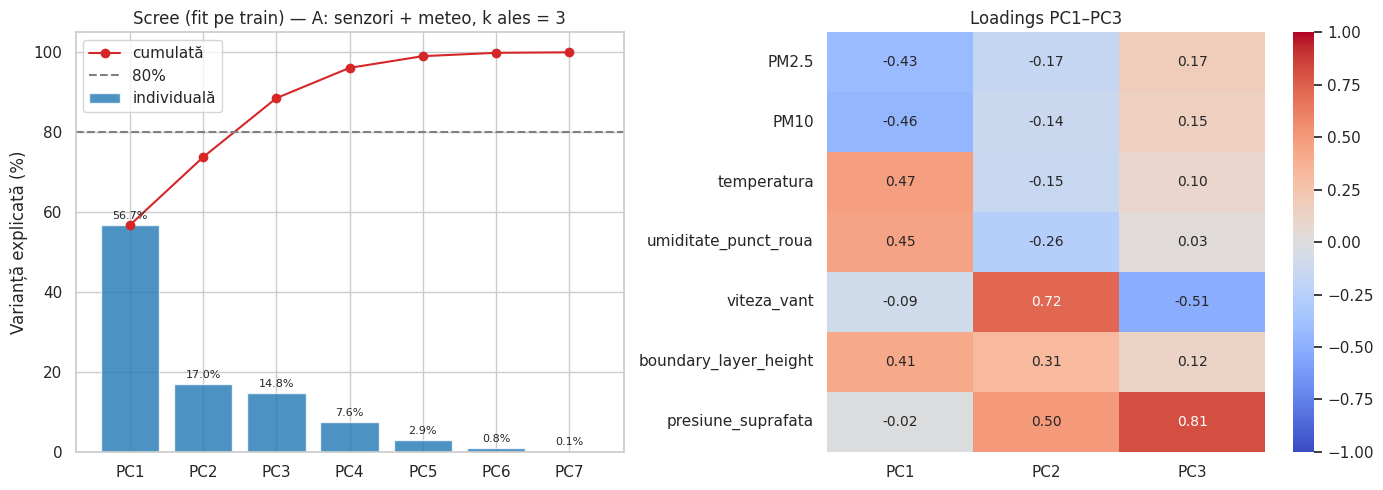

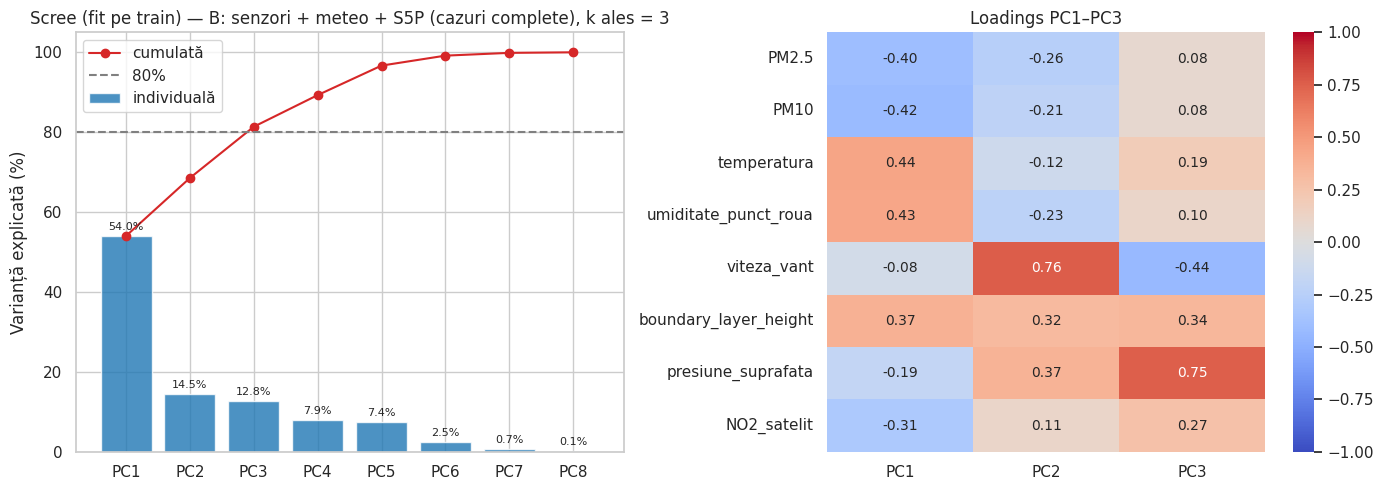

Cele mai mari 3 ponderi (în valoare absolută) pe fiecare componentă. Semnul unei componente e arbitrar;
contează ce trăsături au același semn și care semn opus.

A · PC1: temperatura (+0.47), PM10 (-0.46), umiditate_punct_roua (+0.45)
A · PC2: viteza_vant (+0.72), presiune_suprafata (+0.50), boundary_layer_height (+0.31)
A · PC3: presiune_suprafata (+0.81), viteza_vant (-0.51), PM2.5 (+0.17)
B · PC1: temperatura (+0.44), umiditate_punct_roua (+0.43), PM10 (-0.42)
B · PC2: viteza_vant (+0.76), presiune_suprafata (+0.37), boundary_layer_height (+0.32)
B · PC3: presiune_suprafata (+0.75), viteza_vant (-0.44), boundary_layer_height (+0.34)


In [6]:
for n, r in R.items():
    cols, p = r['cols'], r['pca']; v = p.explained_variance_ratio_ * 100; pcs = [f'PC{i+1}' for i in range(len(cols))]
    L = pd.DataFrame(p.components_.T[:, :3], index=cols, columns=pcs[:3]); r['loadings'] = L
    fig, ax = plt.subplots(1, 2, figsize=(14, 5))
    ax[0].bar(pcs, v, color='#1f77b4', alpha=.8, label='individuală'); ax[0].plot(pcs, np.cumsum(v), 'o-', c='#d62728', label='cumulată')
    ax[0].axhline(VAR_MIN, ls='--', c='gray', label=f'{VAR_MIN}%')
    for i, t in enumerate(v): ax[0].annotate(f'{t:.1f}%', (i, t + 1.5), ha='center', fontsize=8)
    ax[0].set(ylabel='Varianță explicată (%)', title=f'Scree (fit pe train) — {n}, k ales = {K[n]}'); ax[0].legend()
    sns.heatmap(L, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, ax=ax[1]); ax[1].set_title('Loadings PC1–PC3')
    plt.tight_layout(); plt.savefig(f"cp2_pca_{'A' if n.startswith('A') else 'B'}.png", dpi=200); plt.show()

print('Cele mai mari 3 ponderi (în valoare absolută) pe fiecare componentă. Semnul unei componente e arbitrar;')
print('contează ce trăsături au același semn și care semn opus.\n')
for n, r in R.items():
    for pc in ['PC1', 'PC2', 'PC3']:
        top = r['loadings'][pc].reindex(r['loadings'][pc].abs().sort_values(ascending=False).index)[:3]
        print(f"{n[:1]} · {pc}: " + ', '.join(f'{k} ({v:+.2f})' for k, v in top.items()))